<a href="https://colab.research.google.com/github/bu11ymaguire/SKT_FLY_AI_8/blob/main/12_23_vol1_LinearRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Linear Regression MPG

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#재현성을 위해 삶,우주, 그리고 모든 것으로 시드 고정.
import random
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

In [ ]:
np.set_printoptions(precision=4, linewidth = 200) #소수점 4째짜리까지 표시

# 데이터 준비

데이터 로딩

In [ ]:
pip install ucimlrepo
#https://archive.ics.uci.edu/dataset/9/auto+mpg

In [ ]:
from ucimlrepo import fetch_ucirepo

In [ ]:
from ucimlrepo import fetch_ucirepo

auto_mpg_dataset = fetch_ucirepo(id=9)

df = auto_mpg_dataset.data.original

print(df.head())

                    car_name  cylinders  displacement  horsepower  weight  \
0  chevrolet,chevelle,malibu          8         307.0       130.0    3504   
1          buick,skylark,320          8         350.0       165.0    3693   
2         plymouth,satellite          8         318.0       150.0    3436   
3              amc,rebel,sst          8         304.0       150.0    3433   
4                ford,torino          8         302.0       140.0    3449   

   acceleration  model_year  origin   mpg  
0          12.0          70       1  18.0  
1          11.5          70       1  15.0  
2          11.0          70       1  18.0  
3          12.0          70       1  16.0  
4          10.5          70       1  17.0  


#EDA

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   car_name      398 non-null    object 
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   mpg           398 non-null    float64
dtypes: float64(4), int64(4), object(1)
memory usage: 28.1+ KB


In [ ]:
df["horsepower"].unique()

array([130., 165., 150., 140., 198., 220., 215., 225., 190., 170., 160.,  95.,  97.,  85.,  88.,  46.,  87.,  90., 113., 200., 210., 193.,  nan, 100., 105., 175., 153., 180., 110.,  72.,  86.,  70.,
        76.,  65.,  69.,  60.,  80.,  54., 208., 155., 112.,  92., 145., 137., 158., 167.,  94., 107., 230.,  49.,  75.,  91., 122.,  67.,  83.,  78.,  52.,  61.,  93., 148., 129.,  96.,  71.,  98.,
       115.,  53.,  81.,  79., 120., 152., 102., 108.,  68.,  58., 149.,  89.,  63.,  48.,  66., 139., 103., 125., 133., 138., 135., 142.,  77.,  62., 132.,  84.,  64.,  74., 116.,  82.])

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
cylinders,398.0,5.454774,1.701004,3.0,4.000,4.0,8.000,8.0
displacement,398.0,193.425879,104.269838,68.0,104.250,148.5,262.000,455.0
horsepower,392.0,104.469388,38.491160,46.0,75.000,93.5,126.000,230.0
weight,398.0,2970.424623,846.841774,1613.0,2223.750,2803.5,3608.000,5140.0
acceleration,398.0,15.568090,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,76.010050,3.697627,70.0,73.000,76.0,79.000,82.0
origin,398.0,1.572864,0.802055,1.0,1.000,1.0,2.000,3.0
mpg,398.0,23.514573,7.815984,9.0,17.500,23.0,29.000,46.6


## 타겟값

<Axes: xlabel='mpg', ylabel='Count'>

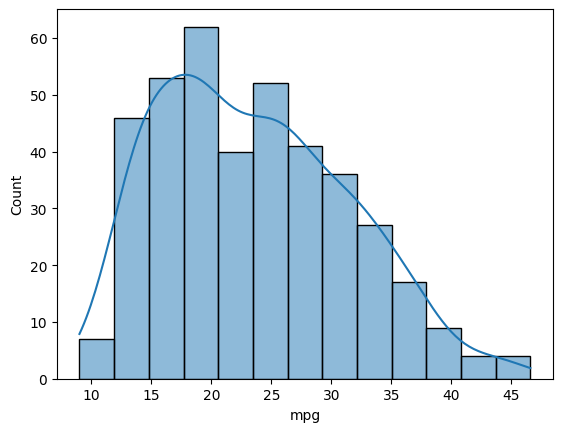

In [ ]:
sns.histplot(data=df, x="mpg",kde= 'True')

##결측치

In [ ]:
df.isna().sum()

,0
car_name,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
mpg,0


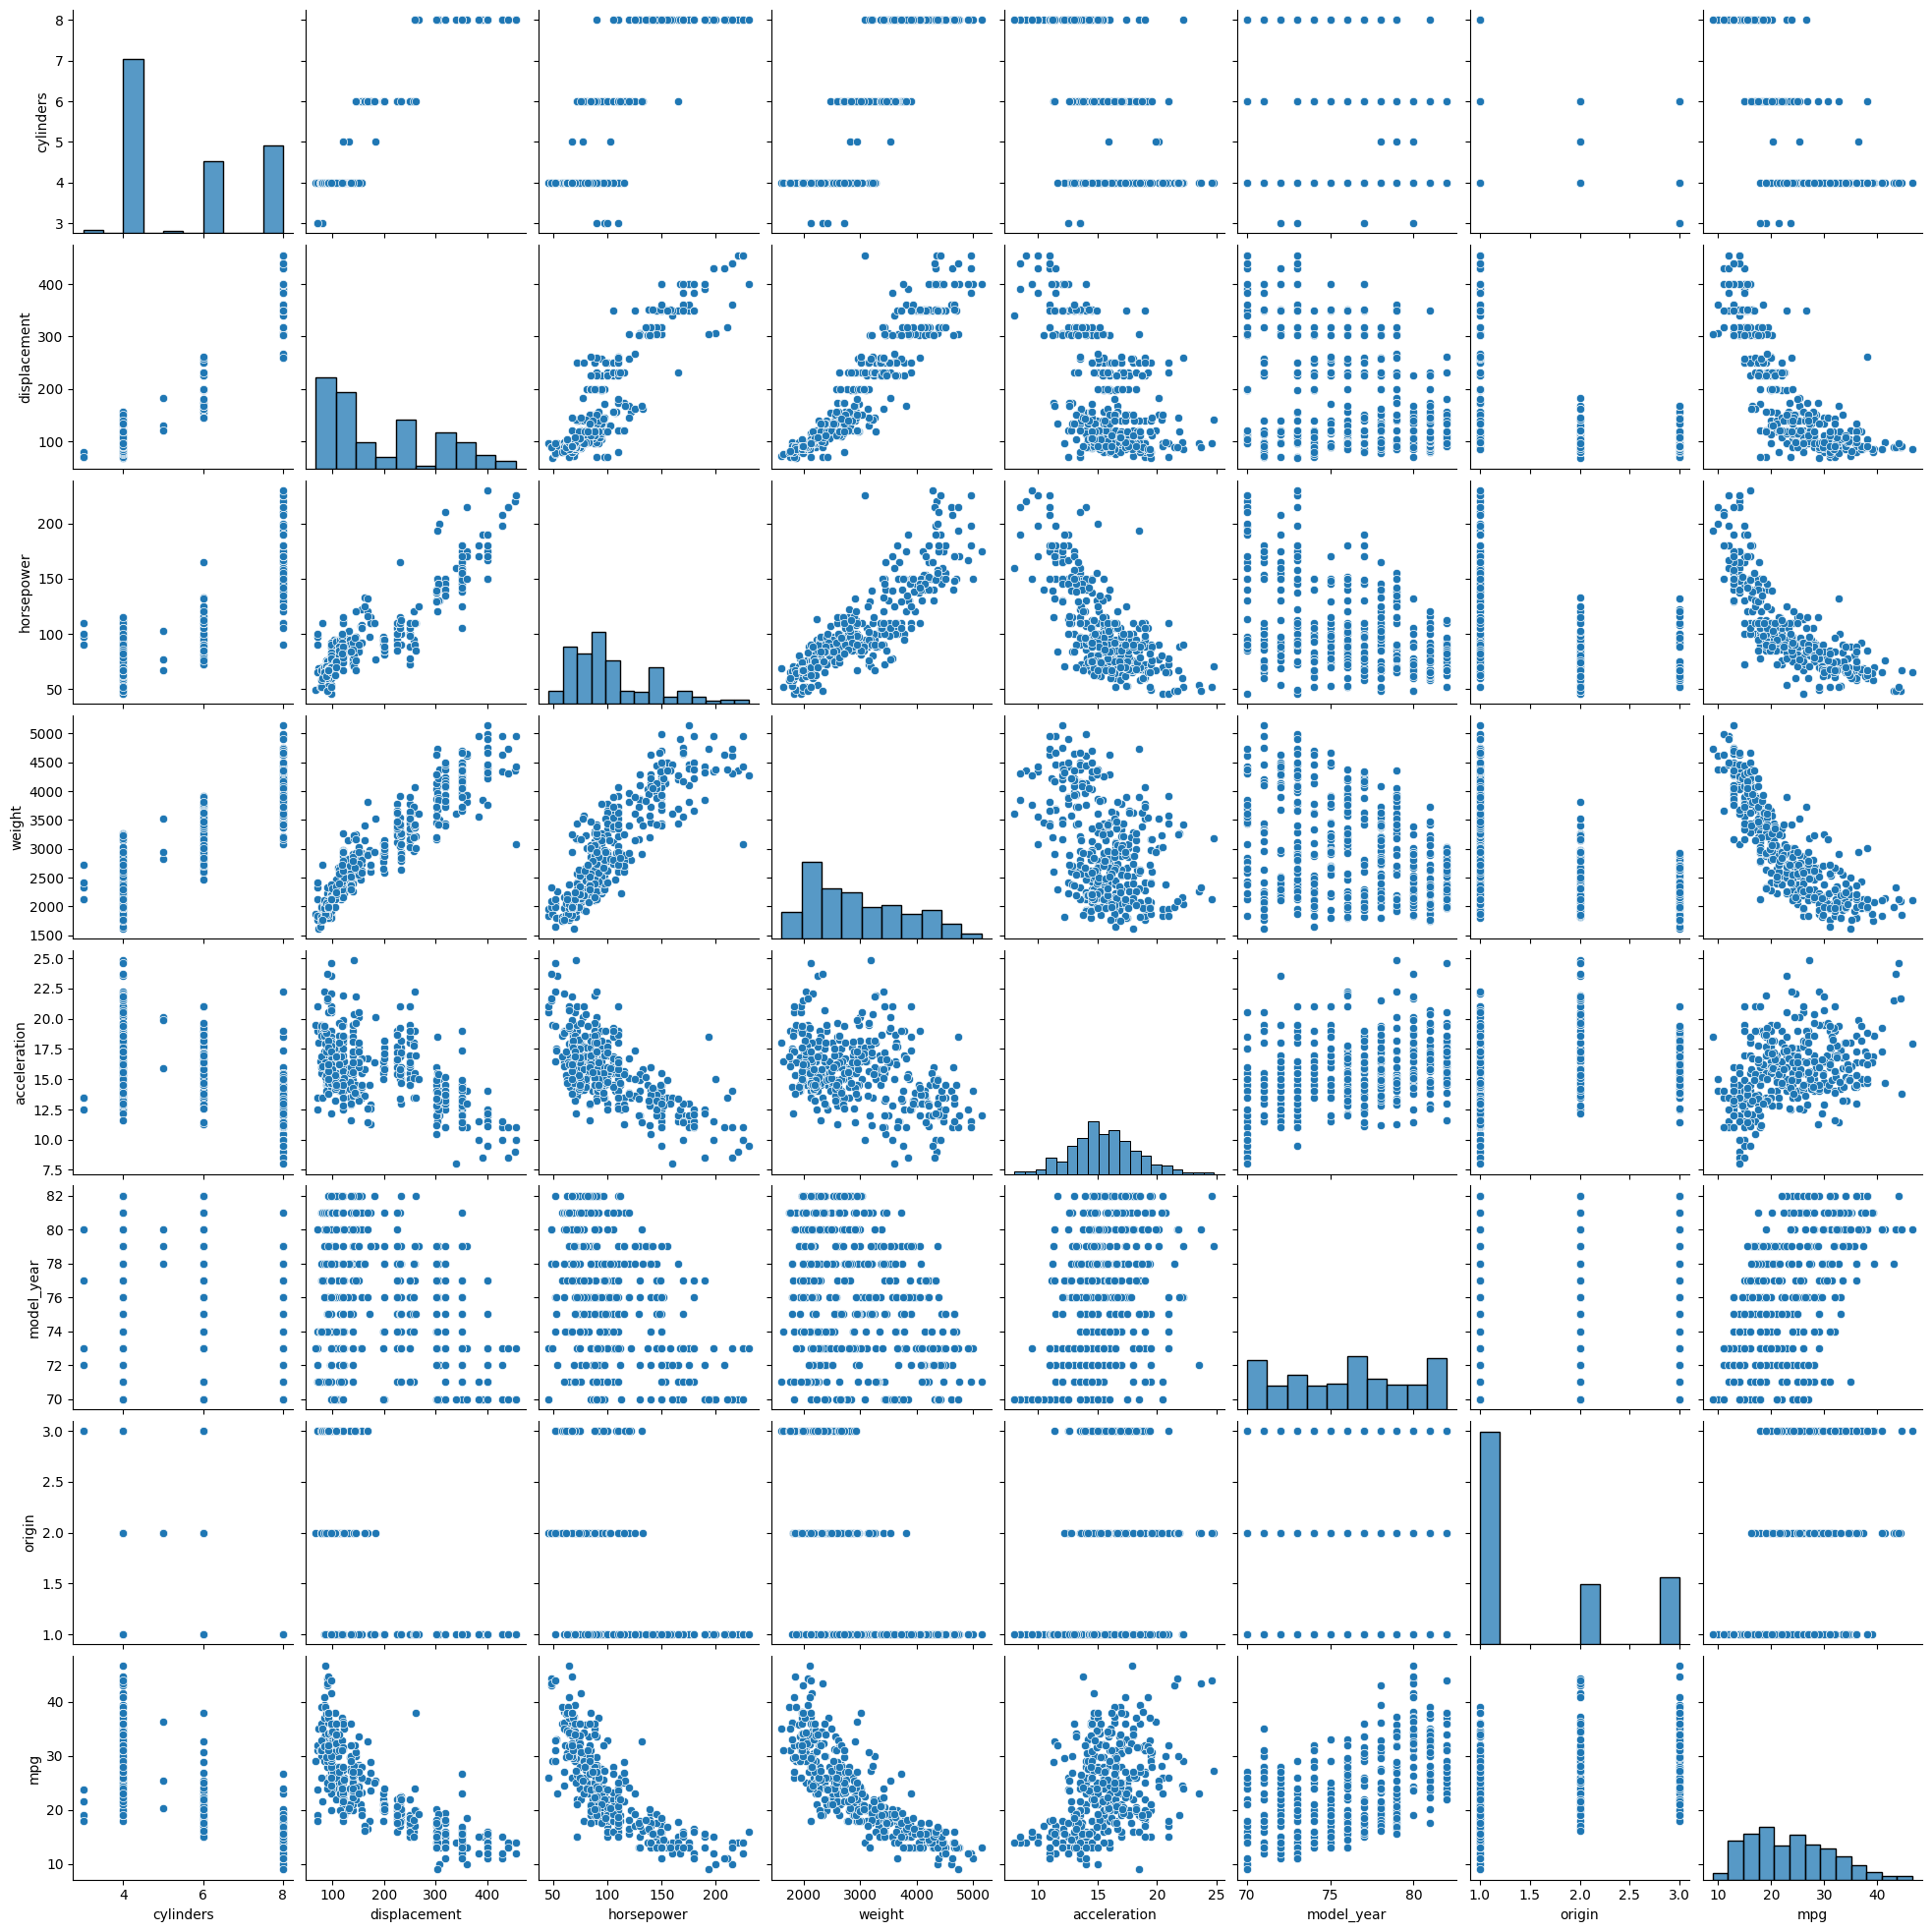

In [ ]:
sns.pairplot(df)

In [ ]:
df["origin"].unique()

array([1, 3, 2])

In [ ]:
df["origin"].value_counts().sort_index()

,count
origin,
1,249
2,70
3,79


## 데이터 분리

In [ ]:
df.shape

(398, 9)

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
train, test = train_test_split(df,test_size=0.2,shuffle=True,random_state=SEED)

In [ ]:
train.shape, test.shape

((318, 9), (80, 9))

In [ ]:
train.head()

,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
3,"amc,rebel,sst",8,304.0,150.0,3433,12.0,70,1,16.0
18,"datsun,pl510",4,97.0,88.0,2130,14.5,70,3,27.0
376,"mazda,glc,custom,l",4,91.0,68.0,2025,18.2,82,3,37.0
248,"honda,civic,cvcc",4,91.0,60.0,1800,16.4,78,3,36.1
177,"audi,100ls",4,115.0,95.0,2694,15.0,75,2,23.0


In [ ]:
x_train = train.drop(["car_name","mpg"],axis = 1)
x_train.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
3,8,304.0,150.0,3433,12.0,70,1
18,4,97.0,88.0,2130,14.5,70,3
376,4,91.0,68.0,2025,18.2,82,3
248,4,91.0,60.0,1800,16.4,78,3
177,4,115.0,95.0,2694,15.0,75,2


In [ ]:
y_train = train["mpg"]
y_train.head()

,mpg
3,16.0
18,27.0
376,37.0
248,36.1
177,23.0


## 데이터 전처리

In [ ]:
# 결측치
x_train.isna().sum()

,0
cylinders,0
displacement,0
horsepower,5
weight,0
acceleration,0
model_year,0
origin,0


In [ ]:
x_train.dropna().isna().sum()

,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model_year,0
origin,0


In [ ]:
x_train['horsepower'].mean(), x_train['horsepower'].median()

(np.float64(103.28434504792332), 92.0)

<Axes: xlabel='horsepower', ylabel='Count'>

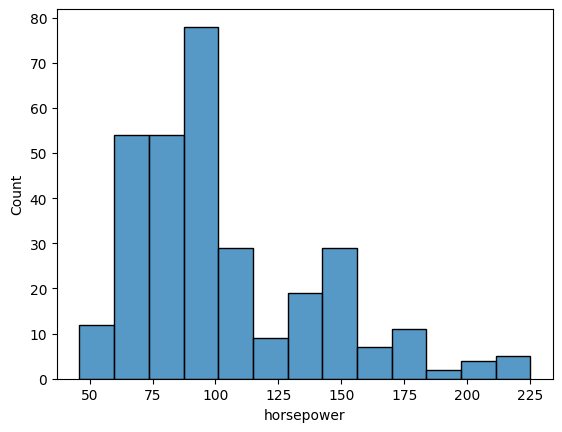

In [ ]:
sns.histplot(x_train['horsepower'])

In [ ]:
x_train['horsepower'] = x_train['horsepower'].fillna(x_train['horsepower'].median())

## 인코딩
- 문자데이터를 숫자로 변환
- 원핫인코딩

In [ ]:
x_train.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
3,8,304.0,150.0,3433,12.0,70,1
18,4,97.0,88.0,2130,14.5,70,3
376,4,91.0,68.0,2025,18.2,82,3
248,4,91.0,60.0,1800,16.4,78,3
177,4,115.0,95.0,2694,15.0,75,2


## 스케일링
- Standard
- Min/Max
- Robust

##수동계산

In [ ]:
mean = np.mean(x_train,axis=0)
mean

,0
cylinders,5.430818
displacement,191.904088
horsepower,103.106918
weight,2969.015723
acceleration,15.639937
model_year,76.103774
origin,1.591195


In [ ]:
std = np.std(x_train,axis=0)
std

,0
cylinders,1.682296
displacement,102.821750
horsepower,37.033572
weight,839.294963
acceleration,2.758921
model_year,3.597508
origin,0.810418


In [ ]:
x_train = (x_train - mean)/ std
x_train.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
3,1.527188,1.090196,1.266232,0.552826,-1.319334,-1.696667,-0.729494
18,-0.850515,-0.922996,-0.407925,-0.999667,-0.413182,-1.696667,1.738368
376,-0.850515,-0.981350,-0.947975,-1.124772,0.927922,1.638975,1.738368
248,-0.850515,-0.981350,-1.163996,-1.392854,0.275493,0.527094,1.738368
177,-0.850515,-0.747936,-0.218907,-0.327675,-0.231952,-0.306816,0.504437


##스카이킷런을 통한 스케일링

In [ ]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

In [ ]:
#ss.fit(x_train)
#ss.transform(x_train)
#ss.fit_transfrom(x_train)

In [ ]:
mean, std

(cylinders          5.430818
 displacement     191.904088
 horsepower       103.106918
 weight          2969.015723
 acceleration      15.639937
 model_year        76.103774
 origin             1.591195
 dtype: float64,
 cylinders         1.682296
 displacement    102.821750
 horsepower       37.033572
 weight          839.294963
 acceleration      2.758921
 model_year        3.597508
 origin            0.810418
 dtype: float64)

In [ ]:
yt_mean = np.mean(y_train,axis = 0)
yt_mean

np.float64(23.60817610062893)

In [ ]:
yt_std = np.std(y_train,axis = 0)
yt_std

7.918094623048821

In [ ]:
y_train.head()

,mpg
3,16.0
18,27.0
376,37.0
248,36.1
177,23.0


In [ ]:
y_train = (y_train - yt_mean) / yt_std
y_train.head()

,mpg
3,-0.960859
18,0.428364
376,1.691294
248,1.577630
177,-0.076808


In [ ]:
y_train.shape

(318,)

In [ ]:
# 스카이킷런 사용 시 (318,)을 (318,1) 형태. 즉, 2차원으로 바꿔줘야 된다 스케일러를 통한 normalization이 가능하다!
# y_train_s = ss.fit_transform(y_train.to_numpy().reshape(318,1))
# y_train_s = y_train_s.reshape(-1)

## 최종 학습데이터

In [ ]:
type(x_train), type(y_train)

(pandas.core.frame.DataFrame, pandas.core.series.Series)

#모델(베이스 라인)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [ ]:
model.coef_, model.intercept_

(array([-0.0334,  0.185 , -0.0625, -0.7147,  0.0237,  0.3611,  0.1355]),
 np.float64(8.309924262932517e-16))

# 테스트
- 결측치
- 인코딩

In [ ]:
test.head()

,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
198,"honda,civic",4,91.0,53.0,1795,17.4,76,3,33.0
396,"ford,ranger",4,120.0,79.0,2625,18.6,82,1,28.0
33,"amc,gremlin",6,232.0,100.0,2634,13.0,71,1,19.0
208,"plymouth,volare,premier,v8",8,318.0,150.0,3940,13.2,76,1,13.0
93,"plymouth,fury,gran,sedan",8,318.0,150.0,4237,14.5,73,1,14.0


In [ ]:
x_test = test.drop(["car_name","mpg"],axis=1)
y_test = test["mpg"]

x_test.shape, y_test.shape

((80, 7), (80,))

In [ ]:
x_test['horsepower'] = x_test['horsepower'].fillna(x_train['horsepower'].median())

In [ ]:
x_test.isna().sum()

,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model_year,0
origin,0


In [ ]:
x_test = (x_test - mean) /std
y_test = (y_test - yt_mean) / yt_std

In [ ]:
x_test, y_test

(     cylinders  displacement  horsepower    weight  acceleration  model_year  \
 198  -0.850515     -0.981350   -1.353013 -1.398812      0.637953   -0.028846   
 396  -0.850515     -0.699308   -0.650948 -0.409887      1.072906    1.638975   
 33    0.338337      0.389956   -0.083895 -0.399163     -0.956873   -1.418697   
 208   1.527188      1.226354    1.266232  1.156905     -0.884381   -0.028846   
 93    1.527188      1.226354    1.266232  1.510773     -0.413182   -0.862757   
 ..         ...           ...         ...       ...           ...         ...   
 249   1.527188      0.662271    0.186131  0.471806     -0.050722    0.527094   
 225   0.338337      0.565016    0.186131  0.656485      0.275493    0.249124   
 367  -0.850515     -0.777113   -0.407925 -0.433716      1.435367    1.638975   
 175  -0.850515     -0.991075   -0.893970 -1.229622     -0.594413   -0.306816   
 285   1.527188      1.099922    0.726181  1.037757     -0.086968    0.805065   
 
        origin  
 198  1.7

##최종 테스트 데이터

In [ ]:
type(x_test), type(y_test), x_test.shape, y_test.shape

(pandas.core.frame.DataFrame, pandas.core.series.Series, (80, 7), (80,))

In [ ]:
model

LinearRegression()

In [ ]:
y_pred = model.predict(x_test)
y_pred

array([ 1.1714,  0.751 , -0.2824, -0.8603, -1.4032,  0.4542,  0.5418, -1.7475, -0.8492, -0.0405, -1.3642,  1.5847,  0.1968, -1.2521,  0.0477, -2.1747,  0.7484, -0.0047, -0.9195,  1.601 ,  0.0133,
       -0.5835,  0.6448,  0.648 , -1.0876,  1.3955,  0.2367,  0.1695, -0.2096, -1.8712,  0.6089,  1.4206, -0.3893,  0.311 ,  1.3443, -1.4685, -0.0855, -0.236 , -1.4247,  0.3966,  0.332 ,  0.4818,
       -0.4369, -2.0646,  0.1175,  1.4311,  0.3981,  0.0737, -0.1386,  0.4994, -0.1171,  1.2711,  1.1447, -1.5982,  0.5173, -1.7176, -0.4853,  0.7915, -0.0549, -0.3958, -0.9383,  1.0719,  0.052 ,
       -0.3927, -0.3386,  0.2404,  0.1907,  1.108 ,  0.5639, -1.3755,  0.968 , -1.3364, -1.7127, -0.5275,  0.4774, -0.187 , -0.39  ,  0.747 ,  0.7232, -0.4448])

In [ ]:
y_test

,mpg
198,1.186122
396,0.554657
33,-0.581980
208,-1.339738
93,-1.213445
...,...
249,-0.468317
225,-0.771420
367,0.554657
175,0.680950


In [ ]:
y_pred_original = (y_pred * yt_std) + yt_mean
y_test_original = (y_test * yt_std) + yt_mean

print("Original y_pred (first 5 values):")
print(y_pred_original[:5])

print("\nOriginal y_test (first 5 values):")
print(y_test_original.head())

Original y_pred (first 5 values):
[32.8837 29.5546 21.3719 16.7963 12.4978]

Original y_test (first 5 values):
198    33.0
396    28.0
33     19.0
208    13.0
93     14.0
Name: mpg, dtype: float64


#평가

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test_original,y_pred_original)
r2 = r2_score(y_test_original,y_pred_original)

mse, r2

(8.249678827527067, 0.8465645437536109)

#Ridge, Lasso

In [ ]:
from sklearn.linear_model import Ridge
ridge = Ridge()
ridge.fit(x_train,y_train)

Ridge()

In [ ]:
y_pred_Ridge = ridge.predict(x_test)
y_pred_Ridge

array([ 1.1622,  0.7504, -0.2909, -0.8602, -1.3943,  0.4517,  0.5452, -1.7591, -0.8359, -0.0273, -1.3779,  1.5779,  0.1905, -1.2452,  0.0497, -2.1588,  0.752 ,  0.0073, -0.9338,  1.5893,  0.0174,
       -0.5805,  0.6282,  0.6453, -1.0872,  1.3776,  0.2411,  0.1719, -0.2146, -1.8625,  0.6126,  1.4104, -0.405 ,  0.3105,  1.3397, -1.4829, -0.0836, -0.2486, -1.4097,  0.398 ,  0.332 ,  0.4735,
       -0.4194, -2.0625,  0.1235,  1.4202,  0.4017,  0.0823, -0.1347,  0.5042, -0.12  ,  1.2683,  1.1404, -1.6068,  0.5178, -1.7198, -0.4981,  0.7927, -0.0583, -0.3919, -0.9529,  1.0633,  0.0547,
       -0.3792, -0.3368,  0.242 ,  0.1931,  1.1035,  0.5565, -1.3629,  0.9696, -1.3261, -1.7261, -0.5355,  0.4742, -0.1885, -0.3897,  0.7445,  0.7244, -0.4477])

In [ ]:
y_pred_Ridge_original = (y_pred_Ridge * yt_std) + yt_mean
y_test_original = (y_test * yt_std) + yt_mean

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

def print_metrics(y_true, y_pred):
   mse = mean_squared_error(y_true, y_pred)
   r2 = r2_score(y_true, y_pred)
   print(f"MSE: {mse:.2f}")
   print(f"R^2: {r2:.2f}")

In [ ]:
print_metrics(y_test_original, y_pred_Ridge_original)

MSE: 8.27
R^2: 0.85


In [ ]:
from sklearn.linear_model import Lasso

lasso = Lasso()
lasso.fit(x_train,y_train)

Lasso()

In [ ]:
y_pred_Lasso = lasso.predict(x_test)
y_pred_Lasso

array([-4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17,
       -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17,
       -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17,
       -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17,
       -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-17,
       -4.7481e-17, -4.7481e-17, -4.7481e-17, -4.7481e-

In [ ]:
y_pred_lass_original = (y_pred_Lasso * yt_std) + yt_mean

print_metrics(y_test_original, y_pred_lass_original)

MSE: 53.98
R^2: -0.00


#모델 저장

In [ ]:
import pickle

horsepower_median = x_train['horsepower'].median()
x_train_mean = mean
x_train_std = std
y_train_mean = yt_mean
y_train_std = yt_std

data_to_save = {
    "name" : "linear_regression, auto - mpg", "horsepower_median" : horsepower_median, "x_train_mean" : x_train_mean, "x_train_std" : x_train_std,
    "y_train_mean" : y_train_mean, "y_train_std" : y_train_std
}

In [ ]:
filename = "lr_autompg.pkl"

with open(filename, "wb") as file:
  pickle.dump(data_to_save, file)

#모델 사용

In [ ]:
with open("lr_autompg.pkl","rb") as file:
  loaded_data = pickle.load(file)

loaded_data

{'name': 'linear_regression, auto - mpg',
 'horsepower_median': -0.2999148547027601,
 'x_train_mean': cylinders          5.430818
 displacement     191.904088
 horsepower       103.106918
 weight          2969.015723
 acceleration      15.639937
 model_year        76.103774
 origin             1.591195
 dtype: float64,
 'x_train_std': cylinders         1.682296
 displacement    102.821750
 horsepower       37.033572
 weight          839.294963
 acceleration      2.758921
 model_year        3.597508
 origin            0.810418
 dtype: float64,
 'y_train_mean': np.float64(23.60817610062893),
 'y_train_std': 7.918094623048821}